# Лабораторная работа №1 Вариант 3

## Импортирование библиотек

In [30]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
import seaborn as sns

## Загрузка DataFrame

In [31]:
df = pd.read_csv('TRANSACTION.csv', encoding='utf-8')

## Задание 1

In [32]:
unique_customers = df['CUSTOMER'].nunique()
unique_products = df['PRODUCT'].nunique()

print(f"Уникальные клиенты: {unique_customers}")
print(f"Уникальные продукты: {unique_products}\n")

Уникальные клиенты: 1001
Уникальные продукты: 20



In [33]:
MIN_SUPPORT = 0.03
MAX_LEN = 4
TARGET_PRODUCT = "bourbon"

## Задание 2

In [34]:
transactions = df.groupby('CUSTOMER')['PRODUCT'].apply(list).values.tolist()

te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

frequent_itemsets = apriori(
    df_encoded, 
    min_support=0.03,
    use_colnames=True, 
    max_len=4  
)

print("Частые наборы (min_support=0.03, max_len=4):")
frequent_itemsets

Частые наборы (min_support=0.03, max_len=4):


,support,itemsets
0,0.313686,(apples)
1,0.304695,(artichok)
2,0.362637,(avocado)
3,0.391608,(baguette)
4,0.073926,(bordeaux)
...,...,...
656,0.037962,"(cracker, heineken, soda, steak)"
657,0.041958,"(cracker, olives, hering, soda)"
658,0.030969,"(hering, ham, olives, steak)"
659,0.102897,"(hering, olives, ham, turkey)"


## Задание 3

In [35]:
filtered_itemsets = []

for index, row in frequent_itemsets.iterrows():
    if TARGET_PRODUCT in row['itemsets']:
        filtered_itemsets.append(row)

target_itemsets = pd.DataFrame(filtered_itemsets)

max_len = target_itemsets['itemsets'].apply(len).max()
largest_set = target_itemsets[
    target_itemsets['itemsets'].apply(len) == max_len
].sort_values('support', ascending=False).iloc[0]
    
print(f"3. Самый большой набор с '{TARGET_PRODUCT}':")
print(f"   Продукты: {largest_set['itemsets']}")
print(f"   Поддержка: {largest_set['support']:.3f}\n")

3. Самый большой набор с 'bourbon':
   Продукты: frozenset({'cracker', 'heineken', 'bourbon', 'soda'})
   Поддержка: 0.121



## Задание 4

In [36]:
MIN_CONFIDENCE = 0.3

rules = association_rules(
    frequent_itemsets, 
    metric="confidence", 
    min_threshold=MIN_CONFIDENCE
)

filtered_rules = []

for index, row in rules.iterrows():
    if TARGET_PRODUCT in row['antecedents']:
        filtered_rules.append(row)

target_rules = pd.DataFrame(filtered_rules)

best_rule = target_rules.sort_values('lift', ascending=False).iloc[0]
    
print(f"4. Лучшее правило для '{TARGET_PRODUCT}':")
print(f"   {best_rule['antecedents']} => {best_rule['consequents']}")
print(f"   Поддержка: {best_rule['support']:.3f}")
print(f"   Достоверность: {best_rule['confidence']:.3f}")
print(f"   Лифт: {best_rule['lift']:.3f}")
print("\nИнтерпретация: Покупатели, которые берут бурбон, ")
print(f"в {best_rule['lift']:.1f} раза чаще покупают сопутствующий продукт.\n")

4. Лучшее правило для 'bourbon':
   frozenset({'bourbon', 'ice_crea'}) => frozenset({'turkey', 'coke'})
   Поддержка: 0.096
   Достоверность: 0.662
   Лифт: 5.569

Интерпретация: Покупатели, которые берут бурбон, 
в 5.6 раза чаще покупают сопутствующий продукт.



## Задание 5

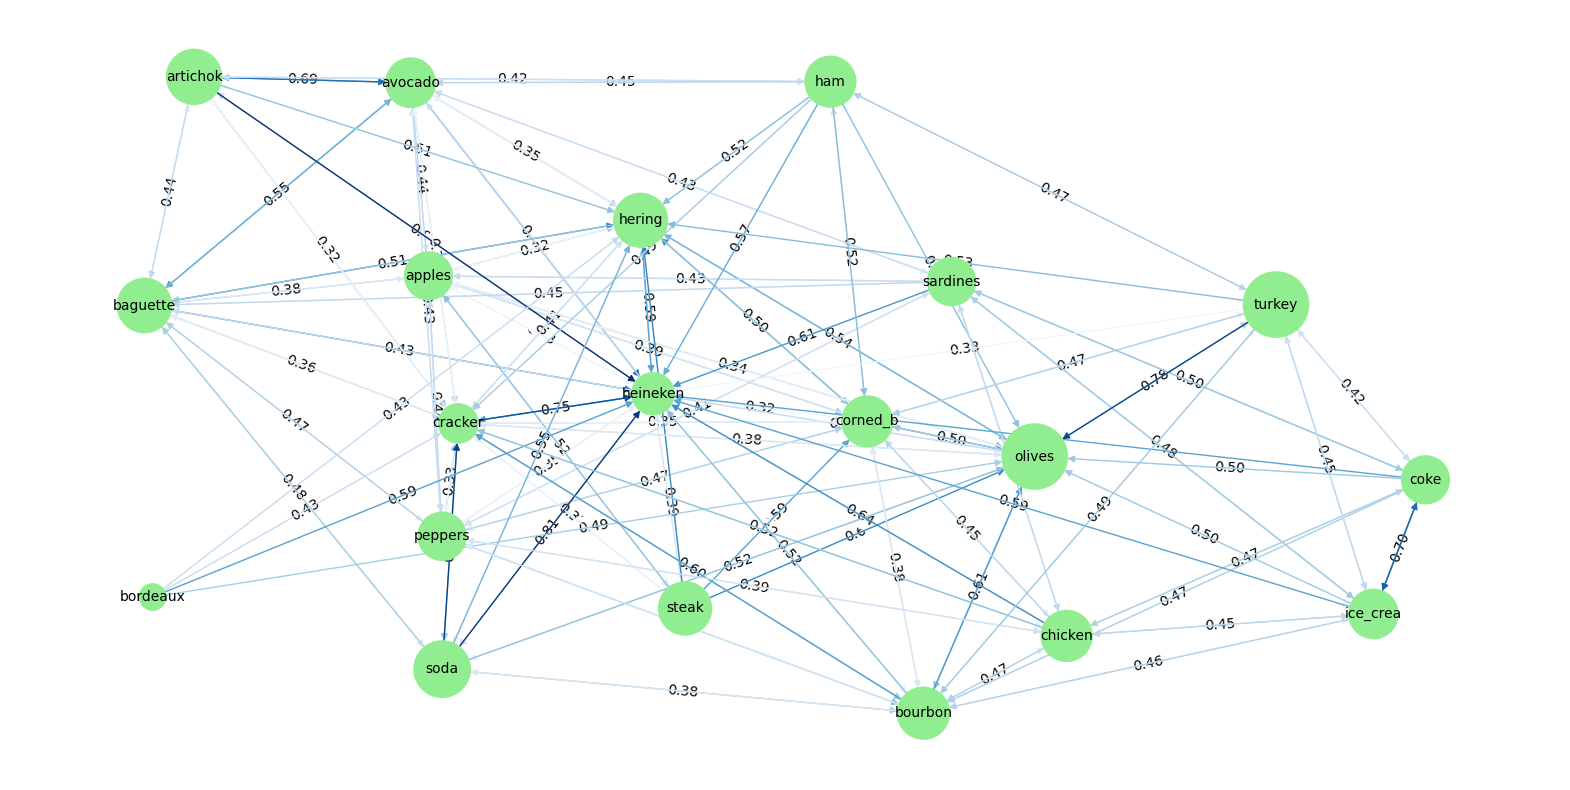

In [37]:
# Фильтрация правил: оставляем только те, где и antecedents, и consequents состоят из одного элемента
filtered_rules = rules.loc[
    (rules['antecedents'].apply(len) == 1) &  # antecedents из одного элемента
    (rules['consequents'].apply(len) == 1)    # consequents из одного элемента
]

# Создание ориентированного графа
G = nx.DiGraph()

# Добавление узлов и ребер в граф
for _, rule in filtered_rules.iterrows():
    antecedent = list(rule['antecedents'])[0]  # Преобразуем frozenset в строку
    consequent = list(rule['consequents'])[0]  # Преобразуем frozenset в строку
    support_value = rule['support']
    confidence_value = rule['confidence']

    # Добавляем узлы с атрибутом support
    G.add_node(antecedent, support=support_value)
    G.add_node(consequent, support=support_value)

    # Добавляем ребро с атрибутом weight (confidence)
    G.add_edge(antecedent, consequent, weight=confidence_value)

# позиционирование узлов для визуализации
node_positions = nx.spring_layout(G, seed=42)

# размер узлов зависит от значения support
node_sizes = [G.nodes[n]['support'] * 10000 for n in G.nodes]

# толщина ребер зависит от значения confidence
edges_with_data = G.edges(data=True)
edge_weights = [d['weight'] * 10 for (u, v, d) in edges_with_data]

# визуализация графа
plt.figure(figsize=(20, 10))

# подписи ребер (confidence)
edge_labels = {(u, v): f"{d['weight']:.2f}" for u, v, d in edges_with_data}
nx.draw_networkx_edge_labels(G, node_positions, edge_labels=edge_labels, font_size=10)

# отрисовка графа
nx.draw(
    G, node_positions,
    with_labels=True,  # Отображаем подписи узлов
    node_size=node_sizes,  # Размер узлов зависит от support
    edge_color=edge_weights,  # Цвет ребер зависит от confidence
    edge_cmap=plt.cm.Blues,  # Цветовая карта для ребер
    font_size=10,  # Размер шрифта для подписей узлов
    node_color='lightgreen',  # Цвет узлов
    alpha=1 # Прозрачность узлов и ребер
)

plt.axis('off')
plt.show()

## Задание 6

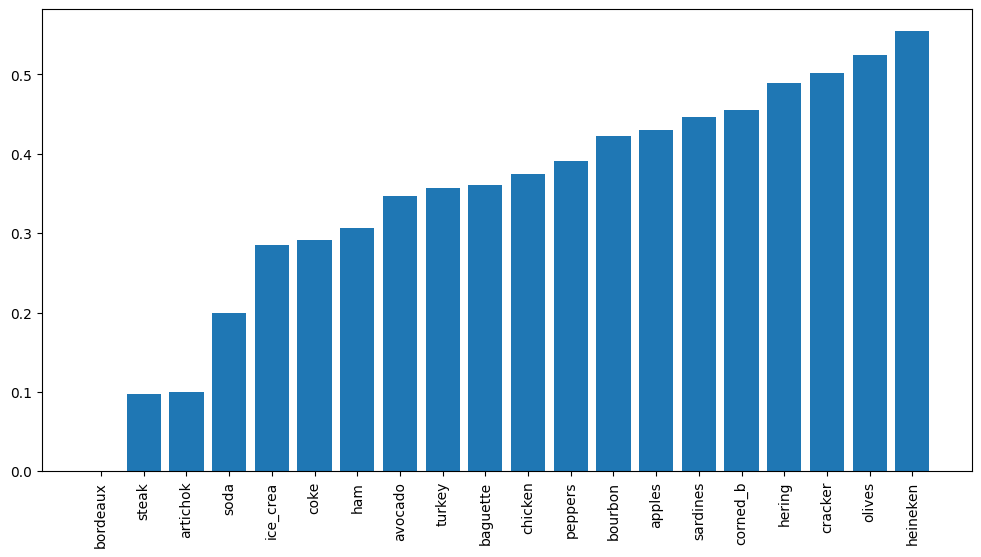

In [38]:
# вычисляем коэффициент кластеризации для каждого узла
metr = nx.clustering(G)

# cортируем коэффициенты кластеризации по возрастанию
metr = dict(sorted(metr.items(), key=lambda x: -x[1]))
metr = {key:1-val for key, val in metr.items()}
# визуализация
plt.figure(figsize=(12, 6))
plt.bar(metr.keys(), metr.values())
plt.xticks(rotation='vertical')
plt.show()


## Задание 7

In [39]:
pivot_table = df.pivot_table(
    index='CUSTOMER', 
    columns='PRODUCT', 
    aggfunc='size', 
    fill_value=0
)

pivot_table

PRODUCT,apples,artichok,avocado,baguette,bordeaux,bourbon,chicken,coke,corned_b,cracker,ham,heineken,hering,ice_crea,olives,peppers,sardines,soda,steak,turkey
CUSTOMER,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,1,0,0,1,0,1,0,1,1,1,0,0,0,0,1
1,0,0,0,1,0,0,0,0,1,1,0,1,1,0,1,0,0,1,0,0
2,0,1,1,0,0,0,0,0,0,1,1,1,0,0,0,0,1,0,0,1
3,0,0,0,0,0,1,0,1,0,0,1,0,0,1,1,1,0,0,0,1
4,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
996,0,1,1,0,0,1,1,0,0,1,1,1,0,0,0,0,0,0,0,0
997,1,0,0,1,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,1
998,0,0,0,1,0,0,0,0,0,1,0,1,1,0,0,0,2,1,0,0


## Задание 8

Число клиентов, купивших 'bourbon': 403
Данные успешно масштабированы.
PCA преобразование выполнено.
Объясненная дисперсия первыми двумя компонентами: 27.97%


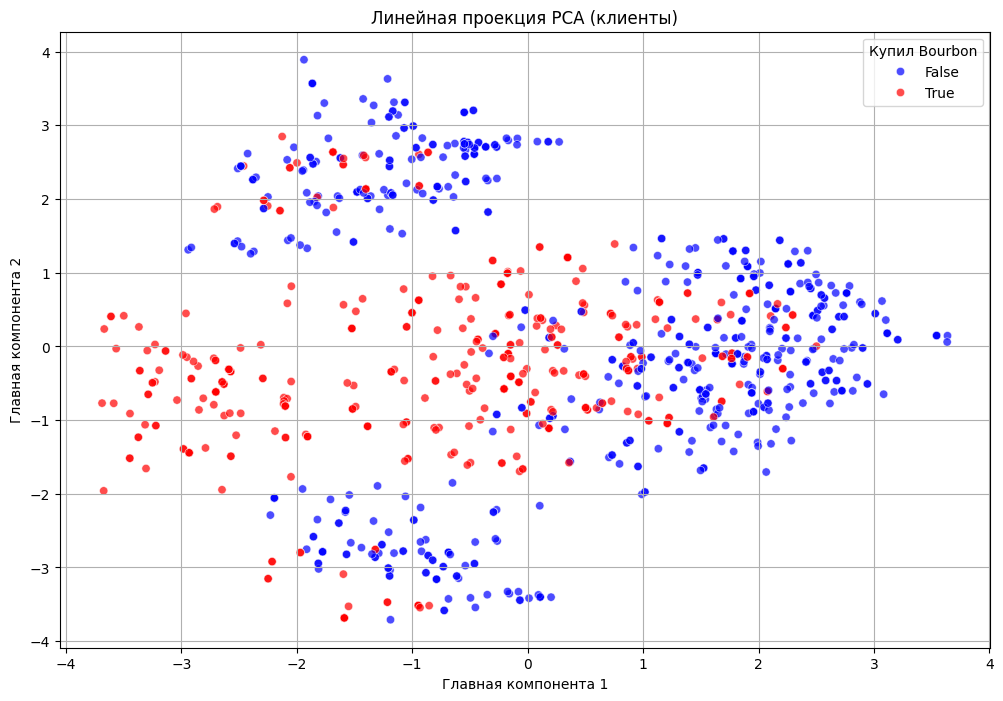

График PCA показан.
--- Пункт 8 завершен ---


In [ ]:
customer_product_matrix = pivot_table

target_product = TARGET_PRODUCT

# Определяем, какие клиенты покупали 'bourbon'
has_target_product = customer_product_matrix[target_product] > 0
print(f"Число клиентов, купивших '{target_product}': {has_target_product.sum()}")

# 1. Масштабирование данных
scaler = StandardScaler()
scaled_data = scaler.fit_transform(customer_product_matrix.copy())
print("Данные успешно масштабированы.")

# 2. Применение PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)
print("PCA преобразование выполнено.")

# Объясненная дисперсия
print(f"Объясненная дисперсия первыми двумя компонентами: {pca.explained_variance_ratio_.sum():.2%}")

# 3. Создание DataFrame для визуализации
pca_df = pd.DataFrame(data=pca_result,
                      columns=['PCA Component 1', 'PCA Component 2'],
                      index=customer_product_matrix.index)
pca_df['Купил Bourbon'] = has_target_product.values

# 4. Визуализация результатов PCA
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x="PCA Component 1",
    y="PCA Component 2",
    hue="Купил Bourbon",
    palette={True: 'red', False: 'blue'},customer_product_matrix = pivot_table

target_product = TARGET_PRODUCT

# Определяем, какие клиенты покупали 'bourbon'
has_target_product = customer_product_matrix[target_product] > 0
print(f"Число клиентов, купивших '{target_product}': {has_target_product.sum()}")

# 1. Масштабирование данных
scaler = StandardScaler()
scaled_data = scaler.fit_transform(customer_product_matrix.copy())
print("Данные успешно масштабированы.")

# 2. Применение PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)
print("PCA преобразование выполнено.")

# Объясненная дисперсия
print(f"Объясненная дисперсия первыми двумя компонентами: {pca.explained_variance_ratio_.sum():.2%}")

# 3. Создание DataFrame для визуализации
pca_df = pd.DataFrame(data=pca_result,
                      columns=['PCA Component 1', 'PCA Component 2'],
                      index=customer_product_matrix.index)
pca_df['Купил Bourbon'] = has_target_product.values

# 4. Визуализация результатов PCA
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x="PCA Component 1",
    y="PCA Component 2",
    hue="Купил Bourbon",
    palette={True: 'red', False: 'blue'},
    data=pca_df,
    legend="full",
    alpha=0.7
)
plt.title(f'Линейная проекция PCA (клиенты)')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.grid(True)
plt.show()
print("График PCA показан.")

print("--- Пункт 8 завершен ---")
    data=pca_df,
    legend="full",
    alpha=0.7
)
plt.title(f'Линейная проекция PCA (клиенты)')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.grid(True)
plt.show()
print("График PCA показан.")

print("--- Пункт 8 завершен ---")

## Задание 9